# 高齢化が進む地域ほど医師は多いのか？
**氏名：＿＿＿＿＿＿＿＿**

- **依頼元：** 都道府県の医療政策担当部署
- **読み手：** 医療政策の担当者
- **調べたい問い：** 高齢化率が高い都道府県ほど、人口10万人当たりの医師数も多いのか。

## 1. 調査の目的
医療政策を考えるとき、医師の人数が多いかどうかだけでなく、地域の人口や年齢構成も考える必要がある。高齢者が多い地域では医療の需要が高くなる可能性があるため、今回は都道府県ごとの高齢化率と人口10万人当たりの医師数を比べる。

先週は人口10万人当たりの医師数を計算し、上位・下位の都道府県を調べた。今回はその計算を再利用し、さらに高齢化率との関係を調べることで分析を発展させる。

## 2. データの読み込みと確認
授業で配布された `japan.csv` を使う。47都道府県について、総人口、65歳以上人口、医師数が記録されている。まずデータの先頭、列の情報、分析に使う項目の基本統計量を確認する。

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# グラフで日本語が文字化けしないようにフォントを設定する
plt.rcParams['font.family'] = 'Noto Sans CJK JP'

# CSVファイルを読み込む
df = pd.read_csv("japan.csv", encoding="utf-8")

# 最初の5行と、分析に使う列を確認する
display(df.head())
display(df[["都道府県", "総人口", "65歳以上人口", "医師数"]].describe())
print("データの行数:", len(df))
print("欠損値の数:")
display(df[["都道府県", "総人口", "65歳以上人口", "医師数"]].isnull().sum())

,Prefecture,都道府県,総人口,日本人人口,15歳未満人口,15～64歳人口,65歳以上人口,外国人人口,出生数,合計特殊出生率,死亡数,転入者数（日本人移動者）,転出者数（日本人移動者）,一般世帯数,一般世帯人員数,単独世帯数,婚姻件数,離婚件数,総面積（北方地域及び竹島を除く）,可住地面積,自然公園面積,県内総生産額（平成27年基準）,県民所得（平成27年基準）,1人当たり県民所得（平成27年基準）,事業所数（民営）,事業所数（民営）（建設業）,事業所数（民営）（製造業）,事業所数（民営）（情報通信業）,事業所数（民営）（卸売業、小売業）,事業所数（民営）（宿泊業、飲食サービス業）,事業所数（民営）（生活関連サービス業、娯楽業）,事業所数（民営）（医療、福祉）,従業者数（民営）,従業者数（民営）（建設業）,従業者数（民営）（製造業）,従業者数（民営）（情報通信業）,従業者数（民営）（卸売業、小売業）,従業者数（民営）（宿泊業、飲食サービス業）,従業者数（民営）（生活関連サービス業、娯楽業）,従業者数（民営）（医療、福祉）,...,高等学校生徒数,短期大学数,大学数,短期大学学生数,大学学生数,公民館数,図書館数,博物館数,劇場、音楽堂等数,社会体育施設数,民間体育施設数,映画館数,一般旅券発行件数,延べ宿泊者数,外国人延べ宿泊者数,総住宅数,空き家数,持ち家数,一戸建住宅数,1住宅当たり延べ面積,総人口（非水洗化人口＋水洗化人口）,非水洗化人口,ごみ総排出量（総量）,1人1日当たりの排出量,ごみのリサイクル率,小売店数,飲食店数,大型小売店数,一般病院数,一般診療所数,歯科診療所数,医師数,歯科医師数,薬剤師数,保育所等数,保育所等在所児数,消費支出（二人以上の世帯）,食料費（二人以上の世帯）,住居費（二人以上の世帯）,教養娯楽費（二人以上の世帯）
0,Hokkaido,北海道,5140000,5098000,530000,2924000,1686000,34321,28762,1.20,69023,49084,53107,2469063,5032739,999825,19326,8662,7842075,2269856,880179,20464601,14892428,2832,216124,21256,10246,2544,51407,27724,18627,19946,2165390,183261,187396,44321,456909,186116,85622,352552,...,112146,15,37,3531,80309,364,165,66,74,3728,1151,19,27026,24664930,741410,2807200,379800,1359400,1255600,91.23,5185414,278541,1781315,941,23.5,36512,22170,822,471,3400,2818,13731,4418,11802,1075,76885,277737,73037,24873,27234
1,Aomori,青森県,1204000,1198000,123000,663000,419000,5409,6513,1.31,18785,16247,20624,509649,1191534,168917,3736,1783,964595,325350,114187,4533207,3291805,2628,55113,5642,2695,390,14097,6755,5978,5112,498418,50709,60863,6018,106856,36321,21542,77912,...,29349,5,10,913,15398,242,35,5,21,697,178,7,3376,3440670,28190,592400,88700,352800,377200,121.58,1246157,153777,455539,1002,14.2,10663,5570,169,76,870,505,2773,735,2345,472,30738,249660,73725,10541,20068
2,Iwate,岩手県,1181000,1173000,125000,648000,408000,6937,6472,1.30,17631,15555,19933,490828,1174106,163290,3673,1459,1527501,375137,72242,4847594,3408836,2781,54598,5292,3483,433,13678,6058,5450,4971,518167,48016,90009,5521,104817,36772,20788,75788,...,29237,4,6,726,11100,174,47,21,27,867,167,8,3659,4268160,22640,579300,93500,338100,352600,119.90,1209697,252040,401035,908,17.1,10434,4769,195,77,888,557,2700,1016,2536,393,28580,285815,77251,18814,25733
3,Miyagi,宮城県,2280000,2256000,258000,1363000,659000,19453,13761,1.15,25897,44528,43566,980549,2251390,362255,8595,3228,728229,318591,171201,9829354,6802912,2943,95305,10458,5087,1145,25004,10306,8298,8116,1031186,96921,121586,21406,224589,78542,37880,134033,...,54112,5,14,2662,49397,434,35,17,42,844,449,11,11763,7625860,59120,1089300,130500,554300,527500,97.24,2269119,193460,808078,976,15.7,16668,8384,375,109,1713,1051,5950,1896,5502,506,40519,287781,78589,22951,26516
4,Akita,秋田県,930000,926000,86000,484000,359000,3651,4335,1.22,16019,10348,13306,383531,923812,117169,2618,1043,1163752,323329,123801,3624750,2637599,2713,44883,4857,3127,282,11368,4976,5265,3851,398671,37900,64599,3374,82750,28088,16828,68859,...,21100,4,7,593,8796,315,49,11,22,857,197,4,2516,2375650,11680,445700,60800,296500,306200,131.93,958311,167201,345947,989,14.6,8797,3908,156,50,822,427,2444,619,2066,272,21915,275545,73628,13191,24327


,総人口,65歳以上人口,医師数
count,4.700000e+01,4.700000e+01,47.000000
mean,2.658426e+06,7.709574e+05,7226.021277
std,2.793536e+06,6.931471e+05,8244.770621
min,5.440000e+05,1.800000e+05,1871.000000
25%,1.046500e+06,3.480000e+05,2855.500000
50%,1.563000e+06,5.230000e+05,4298.000000
75%,2.655000e+06,7.905000e+05,7047.500000
max,1.403800e+07,3.202000e+06,48072.000000


データの行数: 47
欠損値の数:


都道府県       0
総人口        0
65歳以上人口    0
医師数        0
dtype: int64

## 3. 高齢化率と人口10万人当たりの医師数を計算する
高齢化率は「65歳以上人口 ÷ 総人口 × 100」で求める。医師数は都道府県の人口規模による差を小さくするため、「医師数 ÷ 総人口 × 100,000」で計算する。先週と同じように、`for`ループを使って都道府県ごとに計算する。

In [2]:
aging_rates = []
doctor_rates = []

for i in range(len(df)):
    aging = df.loc[i, "65歳以上人口"] / df.loc[i, "総人口"] * 100
    doctor = df.loc[i, "医師数"] / df.loc[i, "総人口"] * 100000
    aging_rates.append(aging)
    doctor_rates.append(doctor)

df["高齢化率"] = aging_rates
df["人口10万人当たりの医師数"] = doctor_rates

display(
    df[["都道府県", "高齢化率", "人口10万人当たりの医師数"]]
    .sort_values("高齢化率", ascending=False)
    .head(10).round(1)
)

,都道府県,高齢化率,人口10万人当たりの医師数
4,秋田県,38.6,262.8
38,高知県,36.1,341.0
34,山口県,35.2,280.4
35,徳島県,34.9,364.6
31,島根県,34.8,320.4
1,青森県,34.8,230.3
5,山形県,34.8,250.5
2,岩手県,34.5,228.6
29,和歌山県,34.0,325.7
43,大分県,34.0,304.4


## 4. 医師数の多い地域・少ない地域を確認する
まず、人口10万人当たりの医師数を基準に上位5都道府県と下位5都道府県を比べる。これにより、医師数の地域差がどの程度あるかを確認する。

In [3]:
sorted_df = df.sort_values("人口10万人当たりの医師数", ascending=False)

print("【人口10万人当たりの医師数 上位5都道府県】")
display(sorted_df[["都道府県", "人口10万人当たりの医師数", "高齢化率"]].head(5).round(1))

print("【人口10万人当たりの医師数 下位5都道府県】")
display(sorted_df[["都道府県", "人口10万人当たりの医師数", "高齢化率"]].tail(5).sort_values("人口10万人当たりの医師数").round(1))

print("47都道府県の平均:", round(df["人口10万人当たりの医師数"].mean(), 1), "人")
print("47都道府県の高齢化率の平均:", round(df["高齢化率"].mean(), 1), "%")

【人口10万人当たりの医師数 上位5都道府県】


,都道府県,人口10万人当たりの医師数,高齢化率
35,徳島県,364.6,34.9
25,京都府,359.1,29.6
30,鳥取県,343.9,33.1
41,長崎県,342.9,33.9
12,東京都,342.4,22.8


【人口10万人当たりの医師数 下位5都道府県】


,都道府県,人口10万人当たりの医師数,高齢化率
10,埼玉県,185.4,27.4
7,茨城県,205.6,30.4
11,千葉県,213.8,28.0
6,福島県,221.1,32.7
14,新潟県,223.1,33.5


47都道府県の平均: 278.1 人
47都道府県の高齢化率の平均: 31.4 %


## 5. 高齢化率と医師数の関係を調べる
高齢化率と人口10万人当たりの医師数の相関係数を計算する。相関係数は、1に近いほど正の関係、-1に近いほど負の関係、0に近いほど直線的な関係が弱いことを表す。あわせて散布図を作り、47都道府県の分布を目で確認する。

高齢化率と人口10万人当たりの医師数の相関係数: 0.175


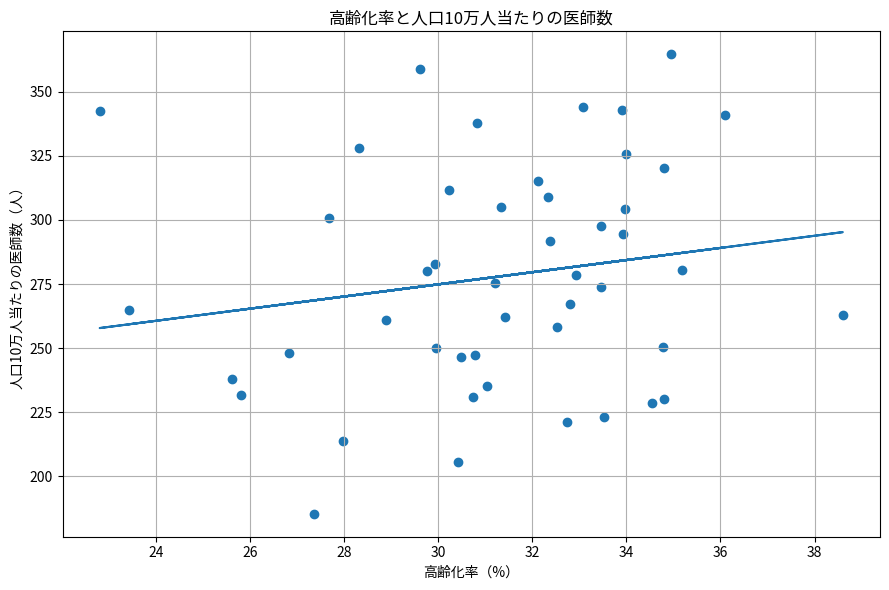

In [4]:
correlation = df["高齢化率"].corr(df["人口10万人当たりの医師数"])
print("高齢化率と人口10万人当たりの医師数の相関係数:", round(correlation, 3))

plt.figure(figsize=(9, 6))
plt.scatter(df["高齢化率"], df["人口10万人当たりの医師数"])

# 全体の傾向を見やすくするため、近似直線を加える
x = df["高齢化率"]
y = df["人口10万人当たりの医師数"]
a, b = np.polyfit(x, y, 1)
plt.plot(x, a * x + b)

plt.title("高齢化率と人口10万人当たりの医師数")
plt.xlabel("高齢化率（%）")
plt.ylabel("人口10万人当たりの医師数（人）")
plt.grid(True)
plt.tight_layout()
plt.show()

## 6. 結果からわかったこと
今回のデータでは、人口10万人当たりの医師数の平均は約278.1人、高齢化率の平均は約31.4%だった。医師数の上位には徳島県、京都府、鳥取県などが入り、下位には埼玉県、茨城県、千葉県などが入った。

高齢化率と人口10万人当たりの医師数の相関係数は約0.175だった。正の値ではあるが0に近いため、今回の47都道府県のデータからは、高齢化率が高いほど医師数も多いという強い関係は確認できなかった。高齢化率が高い秋田県は医師数が平均を下回る一方、高齢化率が低い東京都は医師数が多いなど、地域によって状況が異なっている。

## 7. 組織への提案
医師の配置を考える際には、高齢化率だけを基準にするのではなく、人口10万人当たりの医師数も合わせて確認することを提案する。特に、医師数が少なく高齢化率が高い地域については、医療機関へのアクセスや診療科ごとの医師数など、さらに詳しい情報を調べる必要がある。

今回の分析だけで医師不足の原因や医療の受けやすさを判断することはできない。今後は病院・診療所の所在地、医師の専門分野、患者数などのデータも加えると、支援が必要な地域をより具体的に検討できると考える。

## 8. 先週から改善した点・分析上の注意
先週は人口10万人当たりの医師数を計算し、上位と下位の都道府県をランキングで示した。今回はその分析を残したうえで、高齢化率という別の指標を追加し、相関係数と散布図で2つの項目の関係を調べた点を改善した。

なお、使用したデータは都道府県単位であるため、同じ県内でも市町村によって医師の分布に差がある可能性がある。また、相関が弱いことは高齢化と医療需要に関係がないことを意味しない。今回の結果は、2つの指標の関係を確認したものであり、原因と結果を示すものではない。

**データ出典：** 授業で配布された `japan.csv`